# Preventing Cascading Failures in Urban Drainage Networks Using Graph Theory
Stage 5 implementation (Google Colab ready). Run the cells **top to bottom**.

**Important:** the network is synthetic and the flow routing is a simplified steady-state approximation, not a validated hydraulic simulator. All parameters are illustrative assumptions.

Sections: 1 Setup, 2 Modules, 3 Validation tests, 4 Example figures, 5 Experiments (Stage 6), 6 Paired comparison.

## 1. Setup

In [1]:
import os, sys
os.makedirs('drainage/results', exist_ok=True)
os.chdir('drainage')
sys.path.insert(0, os.getcwd())
import numpy, pandas, networkx, scipy, matplotlib
print('numpy', numpy.__version__, '| networkx', networkx.__version__)

numpy 2.3.3 | networkx 3.6


## 2. Modules (each cell writes one file)

In [2]:
%%writefile cascade.py
"""Flow routing and iterative cascading-failure engine.

APPROXIMATION: steady-state routing on a gravity-oriented DAG. Not a hydraulic simulator.
Rule: a node sends its total inflow q_v only along surviving pipes whose head can still
reach an outlet, split in proportion to the pipes' routing weights w_e. Capacity is NOT
enforced during routing, so L_e > C_e (overload) can occur and triggers failure.
"""
import numpy as np


def route(net, alive, w, theta):
    """Return (load per pipe, unmet demand, reach mask, delivered flow)."""
    head, out, outl, dem = net.head_l, net.out_l, net.outl_l, net.dem_l
    reach = outl[:]
    for v in net.order_rev:                      # low elevation first
        if not reach[v]:
            for e in out[v]:
                if alive[e] and reach[head[e]]:
                    reach[v] = True
                    break
    inflow = [0.0] * net.n
    load = [0.0] * net.m
    unmet = delivered = 0.0
    for v in net.order:                          # high elevation first
        q = theta * dem[v] + inflow[v]
        if outl[v]:
            delivered += q
            continue
        if not reach[v]:
            unmet += theta * dem[v]
            continue
        elig = [e for e in out[v] if alive[e] and reach[head[e]]]
        tot = sum(w[e] for e in elig)
        for e in elig:
            f = q * w[e] / tot
            load[e] = f
            inflow[head[e]] += f
    return np.array(load), unmet, np.array(reach), delivered


def cascade(net, cap, w, theta, F0, record=False):
    """Iterate: route -> mark overloaded pipes failed -> repeat until stable.
    Failures are simultaneous within a round. F only grows, so it terminates."""
    failed = F0.copy()
    history = [failed.copy()] if record else None
    steps = 0
    wl = list(w)
    while True:
        alive = (~failed).tolist()
        load, unmet, reach, delivered = route(net, alive, wl, theta)
        over = (~failed) & (load > cap * (1 + 1e-9))
        if not over.any():
            break
        failed |= over
        steps += 1
        if record:
            history.append(failed.copy())
    return dict(failed=failed, load=load, unmet=unmet, reach=reach,
                delivered=delivered, steps=steps, history=history)

Overwriting cascade.py


In [3]:
%%writefile network.py
"""Synthetic drainage network generator (units: L/s, m).
NOT a validated representation of any real city's drainage infrastructure."""
import numpy as np
from cascade import route


class Network:
    def __init__(self, **kw):
        self.__dict__.update(kw)
        self.m = len(self.tail)
        self.tail_l, self.head_l = self.tail.tolist(), self.head.tolist()
        self.outl_l = self.outlets.tolist()
        self.dem_l = self.demand0.tolist()
        self.order = np.argsort(-self.z).tolist()      # edges go strictly downhill
        self.order_rev = self.order[::-1]
        self.out_l = [[] for _ in range(self.n)]
        for e, (u, v) in enumerate(zip(self.tail_l, self.head_l)):
            self.out_l[u].append(e)
        nb = [set() for _ in range(self.n)]
        for u, v in zip(self.tail_l, self.head_l):
            nb[u].add(v); nb[v].add(u)
        self.nbr_l = [sorted(s) for s in nb]

    def set_scale(self, s):
        """Capacity C_e = max((1 + s*alpha_e) * L0_e, cmin); alpha_e ~ U(0.5, 1.5)."""
        self.scale = s
        self.cap0 = np.maximum((1 + s * self.alpha_raw) * self.load0, self.cmin)


def build_network(seed, rows=7, cols=8, n_outlets=3, thin=0.10, inlet_frac=0.6,
                  scale=0.3, cmin=0.5):
    rng = np.random.default_rng(seed)
    n = rows * cols
    r_idx, c_idx = np.arange(n) // cols, np.arange(n) % cols
    pos = np.c_[c_idx, -r_idx].astype(float)
    z = (rows - 1 - r_idx) * 10.0 + rng.normal(0, 3, n)
    outl = rng.choice(np.arange((rows - 1) * cols, n), n_outlets, replace=False)
    outlets = np.zeros(n, bool); outlets[outl] = True
    z[outl] -= 15
    adj = [(r * cols + c, r * cols + c + 1) for r in range(rows) for c in range(cols - 1)]
    adj += [(r * cols + c, (r + 1) * cols + c) for r in range(rows - 1) for c in range(cols)]
    nbrs = [[] for _ in range(n)]
    for a, b in adj:
        nbrs[a].append(b); nbrs[b].append(a)
    for _ in range(200):                                # fill pits so every node drains
        changed = False
        for v in range(n):
            if not outlets[v] and all(z[w] >= z[v] for w in nbrs[v]):
                z[v] = min(z[w] for w in nbrs[v]) + rng.uniform(0.1, 1.0)
                changed = True
        if not changed:
            break
    edges = []
    for a, b in adj:
        u, v = (a, b) if z[a] > z[b] else (b, a)
        if not outlets[u]:
            edges.append((u, v))
    out_deg = np.bincount([u for u, _ in edges], minlength=n)
    remove, target = set(), int(thin * len(edges))
    for i in rng.permutation(len(edges)):               # thin, keeping out-degree >= 1
        if len(remove) >= target:
            break
        u = edges[i][0]
        if out_deg[u] > 1:
            remove.add(i); out_deg[u] -= 1
    edges = [e for i, e in enumerate(edges) if i not in remove]
    tail = np.array([u for u, _ in edges]); head = np.array([v for _, v in edges])
    m = len(edges)
    in_deg = np.bincount(head, minlength=n)
    inlet = ((rng.random(n) < inlet_frac) | (in_deg == 0)) & ~outlets
    demand0 = np.where(inlet, 2.0 * rng.lognormal(0, 0.5, n), 0.0)
    net = Network(seed=seed, n=n, pos=pos, z=z, outlets=outlets, demand0=demand0,
                  tail=tail, head=head, length=rng.uniform(50, 150, m),
                  g=rng.lognormal(0, 0.4, m), alpha_raw=rng.uniform(0.5, 1.5, m),
                  risk=rng.beta(2, 30, m), cmin=cmin)
    load, unmet, reach, _ = route(net, [True] * m, net.g.tolist(), 1.0)
    assert unmet == 0 and reach.all(), "every node must reach an outlet"
    net.load0 = load
    net.set_scale(scale)
    return net

Overwriting network.py


In [4]:
%%writefile centrality.py
"""Structural importance measures b_e and comparison measures."""
import networkx as nx
import numpy as np
from cascade import route


def to_digraph(net):
    G = nx.DiGraph()
    G.add_nodes_from(range(net.n))
    for e, (u, v) in enumerate(zip(net.tail_l, net.head_l)):
        G.add_edge(u, v, eid=e, length=float(net.length[e]))
    return G


def edge_betweenness_subset(net):
    """Directed edge betweenness, sources = demand nodes, targets = outlets."""
    G = to_digraph(net)
    src = [v for v in range(net.n) if net.demand0[v] > 0]
    tgt = [v for v in range(net.n) if net.outlets[v]]
    bc = nx.edge_betweenness_centrality_subset(G, sources=src, targets=tgt,
                                               normalized=True, weight="length")
    b = np.zeros(net.m)
    for (u, v), val in bc.items():
        b[G[u][v]["eid"]] = val
    return b


def catchment(net):
    """Demand of all nodes upstream of (and including) the pipe's tail."""
    G = to_digraph(net)
    up = {v: net.demand0[v] + sum(net.demand0[a] for a in nx.ancestors(G, v)) for v in range(net.n)}
    return np.array([up[u] for u in net.tail_l])


def oracle(net):
    """Unmet-demand fraction if this single pipe fails (benchmark, not a deployable score)."""
    out = np.zeros(net.m)
    for e in range(net.m):
        alive = [True] * net.m; alive[e] = False
        _, unmet, _, _ = route(net, alive, net.g.tolist(), 1.0)
        out[e] = unmet / net.demand0.sum()
    return out


def utilisation(net):
    return net.load0 / net.cap0


MEASURES = {"bet": edge_betweenness_subset, "catch": catchment, "oracle": oracle}

Overwriting centrality.py


In [5]:
%%writefile strategies.py
"""Priority scores and pipe selection for strategies A-E."""
import numpy as np


def minmax(x):
    lo, hi = float(np.min(x)), float(np.max(x))
    return (x - lo) / (hi - lo) if hi > lo else np.zeros_like(x, float)


def rank01(x):
    return np.argsort(np.argsort(x, kind="stable"), kind="stable") / max(len(x) - 1, 1)


def top_k(score, K):
    return np.argsort(-score, kind="stable")[:K]


def priority(r_obs, b, lam, norm="minmax"):
    f = minmax if norm == "minmax" else rank01
    return lam * f(r_obs) + (1 - lam) * f(b)


def select(name, K, r_obs, b, util, rng, lam=None, norm="minmax"):
    if name == "D_none":
        return np.array([], int)
    if name == "A_risk":
        return top_k(r_obs, K)
    if name == "B_graph":
        return top_k(priority(r_obs, b, lam, norm), K)
    if name == "C_random":
        return rng.choice(len(r_obs), K, replace=False)
    if name == "E_load":
        return top_k(util, K)
    raise ValueError(name)

Overwriting strategies.py


In [6]:
%%writefile evaluate.py
"""Evaluation metrics and paired statistics."""
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon


def largest_cut_region(net, reach):
    cut = [v for v in range(net.n) if not reach[v] and not net.outl_l[v]]
    seen, best = set(), 0
    for s in cut:
        if s in seen:
            continue
        stack, size = [s], 0
        seen.add(s)
        while stack:
            v = stack.pop(); size += 1
            for w in net.nbr_l[v]:
                if w not in seen and not reach[w] and not net.outl_l[w]:
                    seen.add(w); stack.append(w)
        best = max(best, size)
    return best


def metrics(net, res, F0, theta):
    failed = res["failed"]
    nf = int(failed.sum())
    tot = theta * net.demand0.sum()
    return dict(Rf=nf / net.m, secondary=nf - int(F0.sum()),
                RC=net.cap0[~failed].sum() / net.cap0.sum(),     # uses original capacities
                U=res["unmet"] / tot, delivered=res["delivered"] / tot,
                region=largest_cut_region(net, res["reach"]), steps=res["steps"])


def holm(p):
    p = np.asarray(p, float); order = np.argsort(p); m = len(p)
    adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj


def paired_table(df, ref, target, metric, keys=("theta", "budget"), n_boot=2000, seed=0):
    """Paired comparison. diff = ref - target (positive means target is better, lower metric)."""
    piv = df[df.strategy.isin([ref, target])].pivot_table(
        index=list(keys) + ["net", "trial"], columns="strategy", values=metric).reset_index()
    rng = np.random.default_rng(seed)
    rows = []
    for k, g in piv.groupby(list(keys)):
        d = (g[ref] - g[target]).to_numpy()
        boots = rng.choice(d, (n_boot, len(d))).mean(1)
        p = 1.0 if np.allclose(d, 0) else wilcoxon(d).pvalue
        mr = g[ref].mean()
        rows.append(dict(zip(keys, k if isinstance(k, tuple) else (k,)),
                         mean_ref=mr, mean_target=g[target].mean(), mean_diff=d.mean(),
                         ci_lo=np.percentile(boots, 2.5), ci_hi=np.percentile(boots, 97.5),
                         reduction_pct=100 * d.mean() / mr if mr > 0 else np.nan,
                         p_raw=p, n=len(d)))
    out = pd.DataFrame(rows)
    out["p_holm"] = holm(out.p_raw.values)
    return out

Overwriting evaluate.py


In [7]:
%%writefile run_experiments.py
"""Experiment runner. Common random numbers: the same U_e per (network, trial) for all strategies."""
import argparse, os, time
import numpy as np
import pandas as pd
from network import build_network
from cascade import cascade
from centrality import MEASURES, utilisation
from strategies import select
from evaluate import metrics

K_REINF, DELTA = 1.5, 0.5          # capacity multiplier, risk reduction (identical for all strategies)


def calibrate_scale(net, target=0.10, trials=40, seed=12345):
    """Choose capacity margin so Strategy D fails ~target of pipes at theta=1. D only."""
    rng = np.random.default_rng(seed)
    U = rng.random((trials, net.m))
    best, best_gap = None, 9
    for s in np.geomspace(0.1, 8.0, 30):
        net.set_scale(s); rf = []
        for t in range(trials):
            F0 = U[t] < np.minimum(1, net.risk)
            rf.append(cascade(net, net.cap0, net.g, 1.0, F0)["failed"].mean())
        gap = abs(np.mean(rf) - target)
        if gap < best_gap:
            best, best_gap = s, gap
    net.set_scale(best)
    net.calib_gap = best_gap
    return best


def apply_risk_correlation(net, b, rho):
    """True risk = (1-rho)*independent + rho*(same values re-assigned in order of b)."""
    r_ind = net.risk.copy()
    r_sorted = np.sort(r_ind)[np.argsort(np.argsort(b, kind="stable"), kind="stable")]
    net.risk = (1 - rho) * r_ind + rho * r_sorted


def run_network(net_seed, thetas, budgets, trials, lams, n_random=30, sigma=0.0, rho=0.0,
                base_seed=2026, offset=0, scale=None, measure="bet", norm="minmax",
                weight_follows_capacity=True):
    net = build_network(net_seed)
    s = calibrate_scale(net) if scale is None else (net.set_scale(scale) or scale)
    b = MEASURES[measure](net)
    if rho > 0:
        apply_risk_correlation(net, b, rho)
    util = utilisation(net)
    rows = []
    for t in range(trials):
        rng = np.random.default_rng([base_seed, net_seed, offset + t])
        Ue = rng.random(net.m)                                   # common random numbers
        r_obs = net.risk * np.exp(sigma * rng.standard_normal(net.m)) if sigma > 0 else net.risk
        for bud in budgets:
            K = int(np.ceil(bud * net.m))
            sel = {"A_risk": select("A_risk", K, r_obs, b, util, rng),
                   "D_none": select("D_none", K, r_obs, b, util, rng),
                   "E_load": select("E_load", K, r_obs, b, util, rng)}
            for lam in lams:
                sel[f"B_lam{lam:.2f}"] = select("B_graph", K, r_obs, b, util, rng, lam, norm)
            rand = [select("C_random", K, r_obs, b, util, rng) for _ in range(n_random)]
            for theta in thetas:
                def run(idx, name):
                    mask = np.zeros(net.m, bool); mask[idx] = True
                    cap = net.cap0 * np.where(mask, K_REINF, 1.0)
                    w = net.g * np.where(mask, K_REINF, 1.0) if weight_follows_capacity else net.g
                    p = np.minimum(1.0, theta * net.risk * (1 - DELTA * mask))
                    F0 = Ue < p
                    t0 = time.perf_counter()
                    res = cascade(net, cap, w, theta, F0)
                    m = metrics(net, res, F0, theta)
                    m["runtime_ms"] = 1000 * (time.perf_counter() - t0)
                    return m
                for name, idx in sel.items():
                    rows.append(dict(net=net_seed, theta=theta, budget=bud, trial=offset + t,
                                     strategy=name, **run(idx, name)))
                ms = [run(idx, "C") for idx in rand]
                avg = {k: float(np.mean([m[k] for m in ms])) for k in ms[0]}
                rows.append(dict(net=net_seed, theta=theta, budget=bud, trial=offset + t,
                                 strategy="C_random", **avg))
    df = pd.DataFrame(rows)
    df["scale"] = s
    df["sigma"], df["rho"] = sigma, rho
    return df


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--net-seeds", type=int, nargs="+", default=[101, 102, 103, 104, 105])
    ap.add_argument("--trials", type=int, default=100)
    ap.add_argument("--thetas", type=float, nargs="+", default=[0.7, 1.0, 1.3, 1.6])
    ap.add_argument("--budgets", type=float, nargs="+", default=[0.05, 0.10, 0.20])
    ap.add_argument("--lams", type=float, nargs="+", default=[0.0, 0.25, 0.5, 0.75])
    ap.add_argument("--n-random", type=int, default=30)
    ap.add_argument("--sigma", type=float, default=0.0)
    ap.add_argument("--rho", type=float, default=0.0)
    ap.add_argument("--measure", default="bet", choices=list(MEASURES))
    ap.add_argument("--split", default="test", choices=["tune", "test"])
    ap.add_argument("--out", default="results/results.csv")
    a = ap.parse_args()
    os.makedirs(os.path.dirname(a.out) or ".", exist_ok=True)
    off = 0 if a.split == "tune" else 1000
    t0 = time.time()
    dfs = [run_network(s, a.thetas, a.budgets, a.trials, a.lams, a.n_random, a.sigma, a.rho,
                       offset=off, measure=a.measure) for s in a.net_seeds]
    pd.concat(dfs).to_csv(a.out, index=False)
    print(f"saved {a.out} in {time.time() - t0:.1f}s")

Overwriting run_experiments.py


In [8]:
%%writefile plots.py
"""Network, critical-pipe and cascade-example figures."""
import numpy as np
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from cascade import cascade
from centrality import MEASURES
from strategies import priority, top_k


def draw(net, ax, width=None, reinforced=None, failed=None, title=""):
    reinforced = np.zeros(net.m, bool) if reinforced is None else reinforced
    failed = np.zeros(net.m, bool) if failed is None else failed
    width = np.full(net.m, 1.2) if width is None else width
    for e, (u, v) in enumerate(zip(net.tail_l, net.head_l)):
        col = "#d62728" if failed[e] else ("#1f77b4" if reinforced[e] else "#8a8a8a")
        ax.annotate("", xy=net.pos[v], xytext=net.pos[u], zorder=1,
                    arrowprops=dict(arrowstyle="-|>", color=col, lw=width[e],
                                    ls="--" if failed[e] else "-", shrinkA=6, shrinkB=6, mutation_scale=9))
    inl = net.demand0 > 0
    ax.scatter(*net.pos[inl].T, s=40, c="#f2a54a", zorder=2, edgecolor="k", lw=.4)
    ax.scatter(*net.pos[~inl & ~net.outlets].T, s=22, c="white", zorder=2, edgecolor="k", lw=.4)
    ax.scatter(*net.pos[net.outlets].T, s=90, marker="s", c="#2ca02c", zorder=3, edgecolor="k")
    ax.set_title(title, fontsize=10); ax.axis("off")


def make_figures(net, outdir, theta=1.6, budget=0.10, seed=3):
    b = MEASURES["bet"](net)
    K = int(np.ceil(budget * net.m))
    S = priority(net.risk, b, 0.5)
    crit = np.zeros(net.m, bool); crit[top_k(S, K)] = True
    fig, ax = plt.subplots(figsize=(7, 6.5))
    draw(net, ax, title="Synthetic drainage network (orange: inlets, green squares: outlets)")
    fig.savefig(f"{outdir}/fig1_network.png", dpi=200, bbox_inches="tight"); plt.close(fig)
    fig, ax = plt.subplots(figsize=(7, 6.5))
    draw(net, ax, width=0.8 + 4 * S / S.max(), reinforced=crit,
         title=f"Strategy B (lambda=0.5): top {K} pipes (blue); width = priority score")
    fig.savefig(f"{outdir}/fig2_critical_pipes.png", dpi=200, bbox_inches="tight"); plt.close(fig)
    rng = np.random.default_rng(seed); best = None
    for _ in range(200):                                  # pick an illustrative multi-step cascade
        F0 = rng.random(net.m) < np.minimum(1, theta * net.risk)
        r = cascade(net, net.cap0, net.g, theta, F0, record=True)
        if best is None or r["steps"] > best["steps"]:
            best = r
    h = best["history"][:4]
    fig, axs = plt.subplots(1, len(h), figsize=(4 * len(h), 4.2))
    for i, (a, f) in enumerate(zip(np.atleast_1d(axs), h)):
        draw(net, a, failed=f, title=f"{'Initial failures' if i == 0 else f'Round {i}'}: {int(f.sum())} failed")
    fig.suptitle(f"Failure propagation example (theta={theta}, no intervention)")
    fig.savefig(f"{outdir}/fig3_cascade_example.png", dpi=170, bbox_inches="tight"); plt.close(fig)

Overwriting plots.py


In [9]:
%%writefile tests.py
"""Validation tests (Stage 4 list). Run: python tests.py"""
import numpy as np
import networkx as nx
from network import build_network
from cascade import route, cascade
from centrality import to_digraph, MEASURES, utilisation
from strategies import select
from run_experiments import run_network, calibrate_scale

ok = lambda name, cond, info="": print(f"[{'PASS' if cond else 'FAIL'}] {name} {info}") or cond
res = []
nets = [build_network(s) for s in (101, 102, 103, 104, 105)]
for net in nets:
    calibrate_scale(net)
n = nets[0]

gaps=[x.calib_gap for x in nets]
res.append(ok("0 calibration: D failure rate at theta=1 within 0.02 of 0.10", max(gaps)<0.02, f"gaps={[round(g,3) for g in gaps]}, scales={[round(x.scale,2) for x in nets]}"))
res.append(ok("1 DAG and all nodes reach an outlet",
              all(nx.is_directed_acyclic_graph(to_digraph(x)) for x in nets)
              and all(route(x, [True] * x.m, x.g.tolist(), 1.0)[2].all() for x in nets),
              f"pipes={[x.m for x in nets]}"))
rng = np.random.default_rng(0); worst = 0
for x in nets:
    for _ in range(20):
        alive = (rng.random(x.m) > 0.15).tolist(); th = rng.choice([0.7, 1.3, 1.6])
        _, unmet, _, deliv = route(x, alive, x.g.tolist(), th)
        worst = max(worst, abs(unmet + deliv - th * x.demand0.sum()))
res.append(ok("2 flow conservation (delivered + unmet = demand)", worst < 1e-9, f"max err={worst:.2e}"))
over0 = max((route(x, [True] * x.m, x.g.tolist(), 1.0)[0] > x.cap0 * (1 + 1e-9)).sum() for x in nets)
res.append(ok("3 no overload at theta=1, no failures, no reinforcement", over0 == 0, f"overloads={over0}"))
r = cascade(n, n.cap0, n.g, 1.6, rng.random(n.m) < 0.1, record=True)
mono = all((r["history"][i] <= r["history"][i + 1]).all() for i in range(len(r["history"]) - 1))
res.append(ok("4 cascade terminates, failed set only grows", mono and r["steps"] <= n.m,
              f"steps={r['steps']}"))
b = MEASURES["bet"](n); u = utilisation(n); rr = np.random.default_rng(1)
same = all((select("A_risk", K, n.risk, b, u, rr) == select("B_graph", K, n.risk, b, u, rr, 1.0)).all()
           for K in (5, 9, 18))
res.append(ok("5 B at lambda=1 selects same pipes as A", same))
kw = dict(thetas=[1.3], budgets=[0.1], trials=5, lams=[0.5], n_random=3)
d1, d2 = run_network(101, **kw), run_network(101, **kw)
res.append(ok("6 same seed gives identical results",
              d1.drop(columns="runtime_ms").equals(d2.drop(columns="runtime_ms"))))
d = run_network(101, thetas=[0.7, 1.0, 1.3, 1.6], budgets=[0.10], trials=30, lams=[0.5], n_random=5)
mean = d.groupby(["theta", "strategy"]).Rf.mean().unstack()
print(mean.round(4).to_string())
res.append(ok("7 (soft) mean R_f of D >= A, B, E at theta>=1.3",
              bool((mean.loc[[1.3, 1.6], "D_none"] >= mean.loc[[1.3, 1.6], ["A_risk", "B_lam0.50", "E_load"]].max(axis=1) - 1e-9).all())))
print(f"\n{sum(res)}/{len(res)} passed")

Overwriting tests.py


## 3. Validation tests (all should print PASS)

In [10]:
!python tests.py

[PASS] 0 calibration: D failure rate at theta=1 within 0.02 of 0.10 gaps=[np.float64(0.001), np.float64(0.003), np.float64(0.005), np.float64(0.007), np.float64(0.0)], scales=[np.float64(2.78), np.float64(1.77), np.float64(2.78), np.float64(2.05), np.float64(1.52)]
[PASS] 1 DAG and all nodes reach an outlet pipes=[87, 88, 87, 86, 87]
[PASS] 2 flow conservation (delivered + unmet = demand) max err=2.84e-14
[PASS] 3 no overload at theta=1, no failures, no reinforcement overloads=0
[PASS] 4 cascade terminates, failed set only grows steps=1
[PASS] 5 B at lambda=1 selects same pipes as A 
[PASS] 6 same seed gives identical results 
strategy  A_risk  B_lam0.50  C_random  D_none  E_load
theta                                                
0.7       0.0456     0.0444    0.0454  0.0475  0.0406
1.0       0.0828     0.0828    0.0911  0.0981  0.0828
1.3       0.1238     0.1368    0.1473  0.1617  0.1375
1.6       0.1900     0.2061    0.2217  0.2395  0.2138
[PASS] 7 (soft) mean R_f of D >= A, B, E 

## 4. Example figures (network, critical pipes, cascade example)

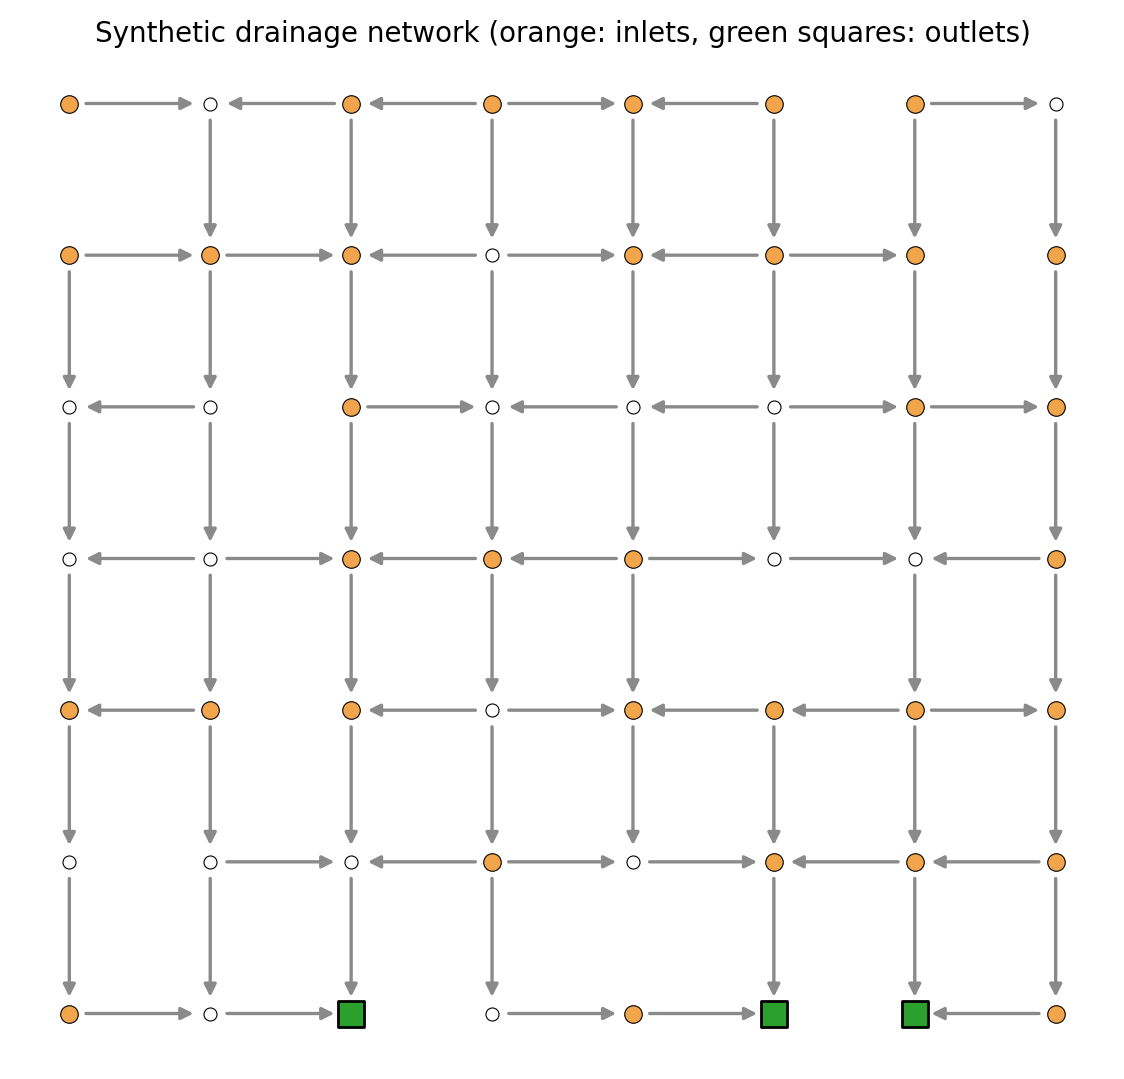

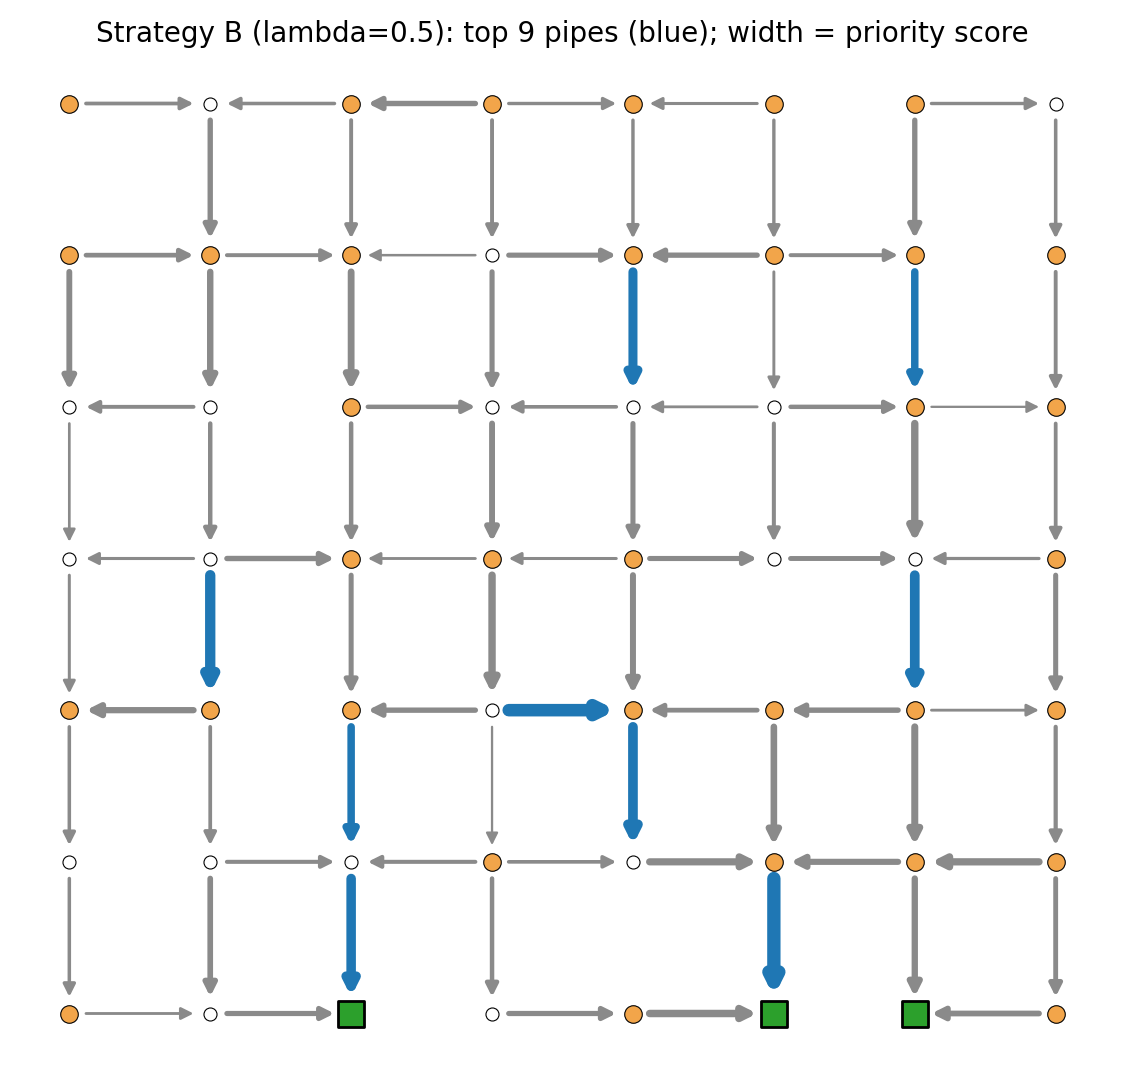

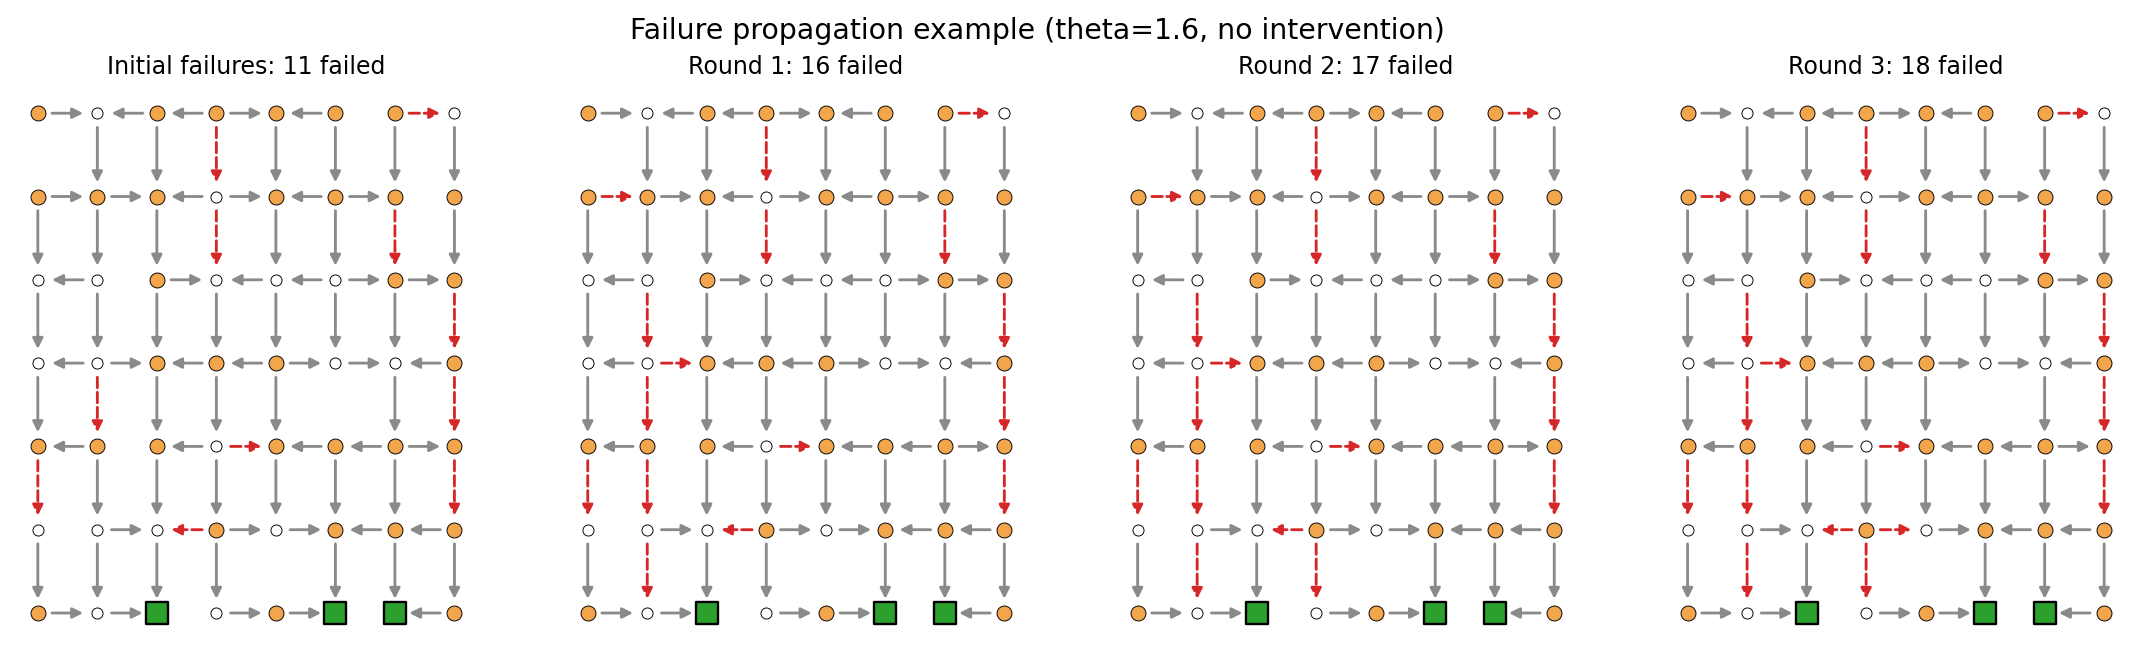

In [11]:
from network import build_network
from run_experiments import calibrate_scale
from plots import make_figures
from IPython.display import Image, display
net = build_network(101); calibrate_scale(net); make_figures(net, 'results')
for f in ['fig1_network','fig2_critical_pipes','fig3_cascade_example']:
    display(Image(f'results/{f}.png'))

## 5. Experiments (Stage 6)
Tune split (seeds 0-999) is used to choose lambda*; the test split (1000+) is used for the headline comparison. Each run takes roughly a minute. Lower `--trials` for a quick check.

In [12]:
!python run_experiments.py --split tune --trials 100 --out results/tune.csv
!python run_experiments.py --split test --trials 100 --out results/test.csv

saved results/tune.csv in 113.9s
saved results/test.csv in 180.4s


Stress tests (E4/E5): noisy risk estimates, risk correlated with structure, alternative importance measure.

In [ ]:
!python run_experiments.py --split test --sigma 0.5 --out results/noise.csv
!python run_experiments.py --split test --rho 0.5 --out results/corr.csv
!python run_experiments.py --split test --measure catch --out results/catch.csv

## 6. Summary and paired comparison against Strategy A
`diff = A - target`; positive means the target strategy is better (lower value). Report results honestly even if B does not beat A.

In [ ]:
import pandas as pd
from evaluate import paired_table
tune = pd.read_csv('results/tune.csv'); test = pd.read_csv('results/test.csv')
print('Tune split: mean R_f by strategy')
print(tune.groupby('strategy').Rf.mean().round(4).to_string())
lam_star = tune[tune.strategy.str.startswith('B_')].groupby('strategy').Rf.mean().idxmin()
print('lambda* (lowest mean R_f on tune set):', lam_star)
print('\nTest split: mean metrics')
print(test.groupby('strategy')[['Rf','U','RC','secondary','region']].mean().round(4).to_string())
for metric in ['Rf','U']:
    print(f'\nPaired {lam_star} vs A_risk on {metric} (Holm-corrected)')
    print(paired_table(test, 'A_risk', lam_star, metric).round(4).to_string(index=False))

In [ ]:
# Download results to your computer (Colab only)
try:
    from google.colab import files
    !zip -rq results.zip results
    files.download('results.zip')
except ImportError:
    print('Not running in Colab; results are in ./results')